# Ejercicios de modelos de regresión — China y México

**Materia:** Tópicos de Big Data
**Tema:** Modelos de regresión aplicados a datos demográficos
**Herramientas:** Python · Jupyter Notebook · Pandas · NumPy · Matplotlib · Scikit-learn

---

Este notebook reutiliza la misma metodología de la práctica
`U3_1_modelos_regresion_demografia`: mismo dataset, misma preparación de los datos,
mismos modelos y mismo estilo de gráficas. Lo único que cambia son las extracciones
de datos que se piden en cada ejercicio.

## Ejercicios

1. **Ejercicio 1 — China:** se extraen los datos de China y se aplican los tres modelos.
2. **Ejercicio 2 — México desde el año 2000:** se extraen los datos de México a partir
   del año 2000 y se aplican los tres modelos a **nacimientos** y a **defunciones**.

# PARTE 1. Importar las bibliotecas

Se utilizan exactamente las mismas bibliotecas del notebook original:

* **Pandas** para trabajar con el dataset.
* **NumPy** para trabajar con arreglos y preparar datos.
* **Matplotlib** para visualizar los datos y las predicciones.
* **Scikit-learn** para construir los modelos de Machine Learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestRegressor

# PARTE 2. Cargar y preparar el dataset

Se utiliza el mismo dataset del notebook original: *Births and deaths projected to 2100*
de **Our World in Data (OWID)**. Se intenta descargar desde internet y, si falla, se lee
el archivo local que está en la carpeta `data/`.

In [3]:
url = "https://ourworldindata.org/grapher/births-and-deaths-projected-to-2100.csv?v=1&csvType=full&useColumnShortNames=true"

try:
    df = pd.read_csv(
        url,
        storage_options={
            "User-Agent": "Our World In Data data fetch/1.0"
        }
    )
except Exception as error:
    print("No fue posible descargar el archivo desde internet:", error)
    print("Se utilizará el archivo local 'births-and-deaths-projected-to-2100.csv'")
    df = pd.read_csv("../data/births-and-deaths-projected-to-2100.csv")

df.head()

No fue posible descargar el archivo desde internet: <urlopen error Tunnel connection failed: 403 Forbidden>
Se utilizará el archivo local 'births-and-deaths-projected-to-2100.csv'


,entity,code,year,deaths__sex_all__age_all__variant_estimates,deaths__sex_all__age_all__variant_medium__projected,births__sex_all__age_all__variant_estimates,births__sex_all__age_all__variant_medium__projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN


## Renombrar las columnas

Igual que en el notebook original, los nombres originales son muy largos, así que los
renombramos para poder trabajar más cómodos.

In [4]:
df = df.rename(columns={
    "entity": "Entity",
    "code": "Code",
    "year": "Year",
    "births__sex_all__age_all__variant_estimates": "births_estimates",
    "births__sex_all__age_all__variant_medium__projected": "births_projected",
    "deaths__sex_all__age_all__variant_estimates": "deaths_estimates",
    "deaths__sex_all__age_all__variant_medium__projected": "deaths_projected",
})


df.head()

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN


## Crear las columnas unificadas

Los datos históricos y las proyecciones de OWID vienen en columnas separadas. Creamos
las columnas `births` y `deaths` con el dato histórico cuando existe y la proyección
cuando no, tal como se hizo en el notebook original.

In [5]:
# Columna unificada: dato histórico si existe; si no, la proyección de OWID
df["births"] = df["births_estimates"].fillna(df["births_projected"])
df["deaths"] = df["deaths_estimates"].fillna(df["deaths_projected"])

df.head()

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
0,Afghanistan,AFG,1950,290972.0,NaN,383985.0,NaN,383985.0,290972.0
1,Afghanistan,AFG,1951,288752.0,NaN,391002.0,NaN,391002.0,288752.0
2,Afghanistan,AFG,1952,288059.0,NaN,397663.0,NaN,397663.0,288059.0
3,Afghanistan,AFG,1953,287712.0,NaN,404666.0,NaN,404666.0,287712.0
4,Afghanistan,AFG,1954,289189.0,NaN,410428.0,NaN,410428.0,289189.0


## Modelos que se van a utilizar

En los dos ejercicios se aplican los mismos tres modelos del notebook original:

1. **Regresión lineal** (`LinearRegression`).
2. **Regresión polinomial** (`PolynomialFeatures` de grado 2 + `LinearRegression`).
3. **Random Forest Regressor** (`RandomForestRegressor` con `n_estimators=100` y
   `random_state=42`).

En los tres casos la variable predictora (**X**) es el **año** y la variable objetivo
(**y**) es el número de nacimientos o de defunciones. Los modelos se entrenan con los
datos históricos (hasta 2023) y después se usan para proyectar de 2024 a 2100.

In [6]:
# Años para los que se van a generar las proyecciones (igual que en el notebook original)
anios_futuros = np.arange(2024, 2101).reshape(-1, 1)

X_futuro = pd.DataFrame(anios_futuros, columns=["Year"])

print("Forma:", X_futuro.shape)
X_futuro.head()

Forma: (77, 1)


,Year
0,2024
1,2025
2,2026
3,2027
4,2028


---

# EJERCICIO 1 — CHINA

## 1. Extracción de los datos de China

Filtramos el dataset para quedarnos únicamente con China, igual que en el notebook
original se hizo con México.

In [7]:
pais = "China"

df_china = df[df["Entity"] == pais]

df_china.head()

,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
7097,China,CHN,1950,12564023.0,NaN,22293376.0,NaN,22293376.0,12564023.0
7098,China,CHN,1951,12411701.0,NaN,22144814.0,NaN,22144814.0,12411701.0
7099,China,CHN,1952,12459848.0,NaN,25496318.0,NaN,25496318.0,12459848.0
7100,China,CHN,1953,12309525.0,NaN,24139416.0,NaN,24139416.0,12309525.0
7101,China,CHN,1954,12145578.0,NaN,25438544.0,NaN,25438544.0,12145578.0


## 2. Visualización de los datos obtenidos

In [8]:
print("Rango de años:", df_china["Year"].min(), "-", df_china["Year"].max())
print("Número de filas:", df_china.shape[0])

Rango de años: 1950 - 2100
Número de filas: 151


In [9]:
df_china[["Entity", "Year", "births", "deaths"]]

,Entity,Year,births,deaths
7097,China,1950,22293376.0,12564023.0
7098,China,1951,22144814.0,12411701.0
7099,China,1952,25496318.0,12459848.0
7100,China,1953,24139416.0,12309525.0
7101,China,1954,25438544.0,12145578.0
...,...,...,...,...
7243,China,2096,3128414.0,14043346.0
7244,China,2097,3120410.0,13941769.0
7245,China,2098,3111630.0,13848117.0
7246,China,2099,3109207.0,13753666.0


Graficamos primero los datos tal cual, para ver cómo se comportan los nacimientos de
China a lo largo del tiempo.

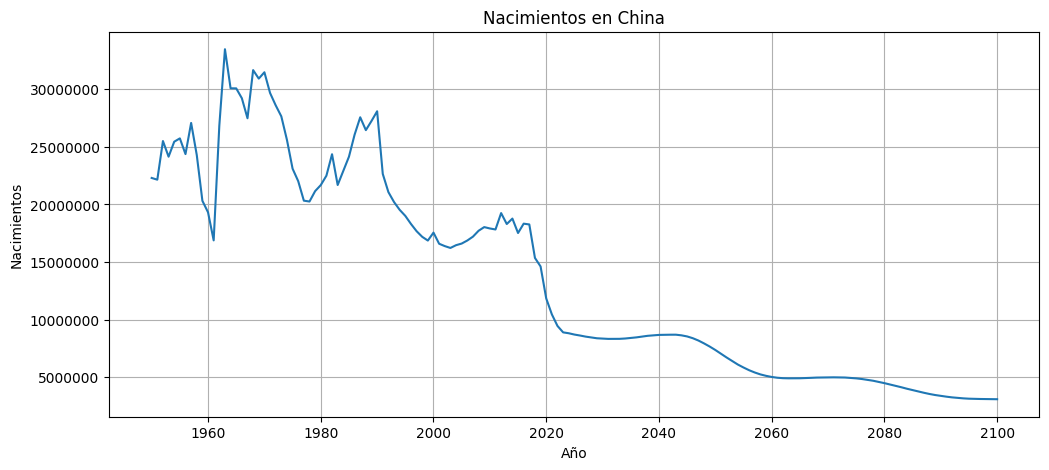

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_china["Year"],
    df_china["births"]
)

plt.title("Nacimientos en China")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.grid()
plt.show()

## 3. Preparación de las variables

Separamos los datos históricos (hasta 2023) de las proyecciones de OWID (después de
2023), exactamente igual que en el notebook original.

In [11]:
df_china_historico = df_china[
    df_china["Year"] <= 2023
]

df_china_proyectado = df_china[
    df_china["Year"] > 2023
]

print("Histórico  ->", df_china_historico.shape, "| años:", df_china_historico["Year"].min(), "a", df_china_historico["Year"].max())
print("Proyectado ->", df_china_proyectado.shape, "| años:", df_china_proyectado["Year"].min(), "a", df_china_proyectado["Year"].max())

Histórico  -> (74, 9) | años: 1950 a 2023
Proyectado -> (77, 9) | años: 2024 a 2100


In [12]:
# Comprobamos que no falten datos en las columnas que vamos a usar
df_china_historico[["Year", "births", "deaths"]].isna().sum()

Year      0
births    0
deaths    0
dtype: int64

Definimos la variable predictora **X** (el año) y la variable objetivo **y**
(los nacimientos), igual que en el notebook original.

In [13]:
X_china = df_china_historico[["Year"]]
y_china_nacimientos = df_china_historico["births"]

print("X_china.shape:", X_china.shape)
print("y_china_nacimientos.shape:", y_china_nacimientos.shape)

X_china.shape: (74, 1)
y_china_nacimientos.shape: (74,)


## 4. Modelo 1 — Regresión lineal (China)

In [14]:
modelo_lineal_china = LinearRegression()

modelo_lineal_china.fit(X_china, y_china_nacimientos)

print("Pendiente (a):", modelo_lineal_china.coef_[0])
print("Intercepto (b):", modelo_lineal_china.intercept_)

Pendiente (a): -187208.31004813028
Intercepto (b): 393489519.9376378


In [15]:
# Predicciones sobre los años históricos y proyección hasta 2100
predicciones_lineal_china = modelo_lineal_china.predict(X_china)

predicciones_lineal_china_futuras = modelo_lineal_china.predict(X_futuro)

print(predicciones_lineal_china_futuras[:10])

[14579900.40022212 14392692.09017396 14205483.78012586 14018275.47007769
 13831067.16002959 13643858.84998149 13456650.53993332 13269442.22988522
 13082233.91983706 12895025.60978895]


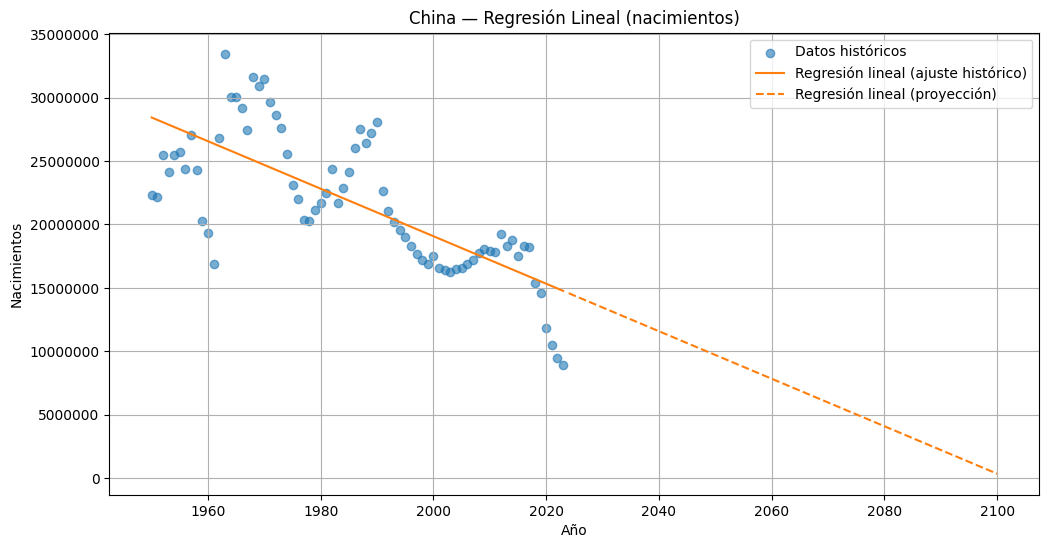

In [16]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_china_historico["Year"],
    df_china_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_china_historico["Year"],
    predicciones_lineal_china,
    color="tab:orange",
    label="Regresión lineal (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_china_futuras,
    color="tab:orange",
    linestyle="--",
    label="Regresión lineal (proyección)"
)

plt.title("China — Regresión Lineal (nacimientos)")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## 5. Modelo 2 — Regresión polinomial (China)

Usamos `PolynomialFeatures` de grado 2, igual que en el notebook original.

In [17]:
poly_china = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_china_poly = poly_china.fit_transform(X_china)

X_china_poly[:5]

array([[1.950000e+03, 3.802500e+06],
       [1.951000e+03, 3.806401e+06],
       [1.952000e+03, 3.810304e+06],
       [1.953000e+03, 3.814209e+06],
       [1.954000e+03, 3.818116e+06]])

In [18]:
modelo_polinomial_china = LinearRegression()

modelo_polinomial_china.fit(
    X_china_poly,
    y_china_nacimientos
)

predicciones_polinomiales_china = modelo_polinomial_china.predict(
    X_china_poly
)

anios_futuros_poly_china = poly_china.transform(
    X_futuro
)

predicciones_polinomiales_china_futuras = modelo_polinomial_china.predict(
    anios_futuros_poly_china
)

print(predicciones_polinomiales_china_futuras[:10])

[10857665.91793251 10372678.84929848  9879855.49754715  9379195.86267471
  8870699.94468117  8354367.74356842  7830199.25933456  7298194.4919796
  6758353.44150352  6210676.10790825]


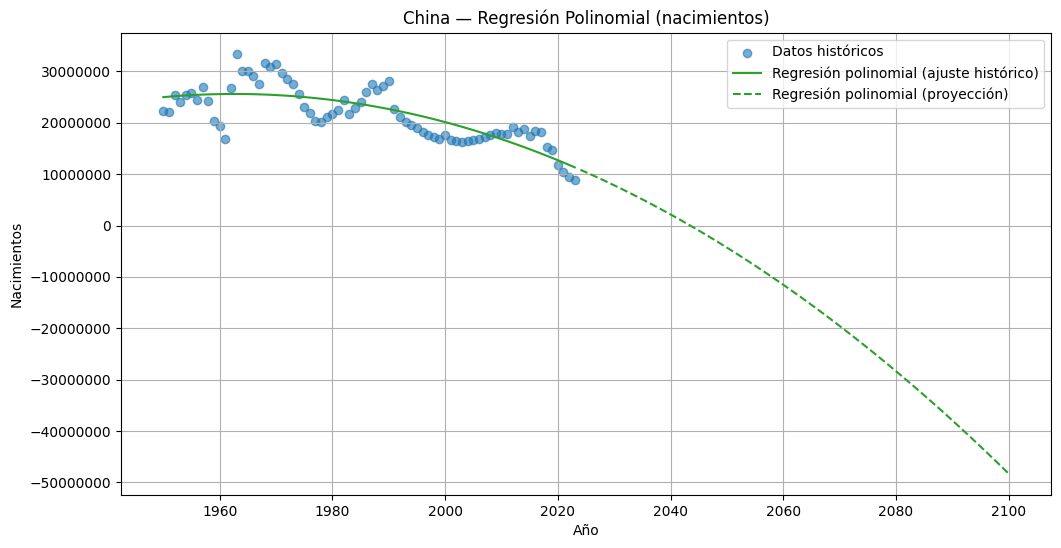

In [19]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_china_historico["Year"],
    df_china_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_china_historico["Year"],
    predicciones_polinomiales_china,
    color="tab:green",
    label="Regresión polinomial (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_china_futuras,
    color="tab:green",
    linestyle="--",
    label="Regresión polinomial (proyección)"
)

plt.title("China — Regresión Polinomial (nacimientos)")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## 6. Modelo 3 — Random Forest Regressor (China)

Mismos parámetros que en el notebook original: `n_estimators=100` y `random_state=42`.

In [20]:
modelo_rf_china = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_rf_china.fit(
    X_china,
    y_china_nacimientos
)

predicciones_rf_china = modelo_rf_china.predict(X_china)

predicciones_rf_china_futuras = modelo_rf_china.predict(
    X_futuro
)

print(predicciones_rf_china_futuras[:10])

[9489420.42 9489420.42 9489420.42 9489420.42 9489420.42 9489420.42
 9489420.42 9489420.42 9489420.42 9489420.42]


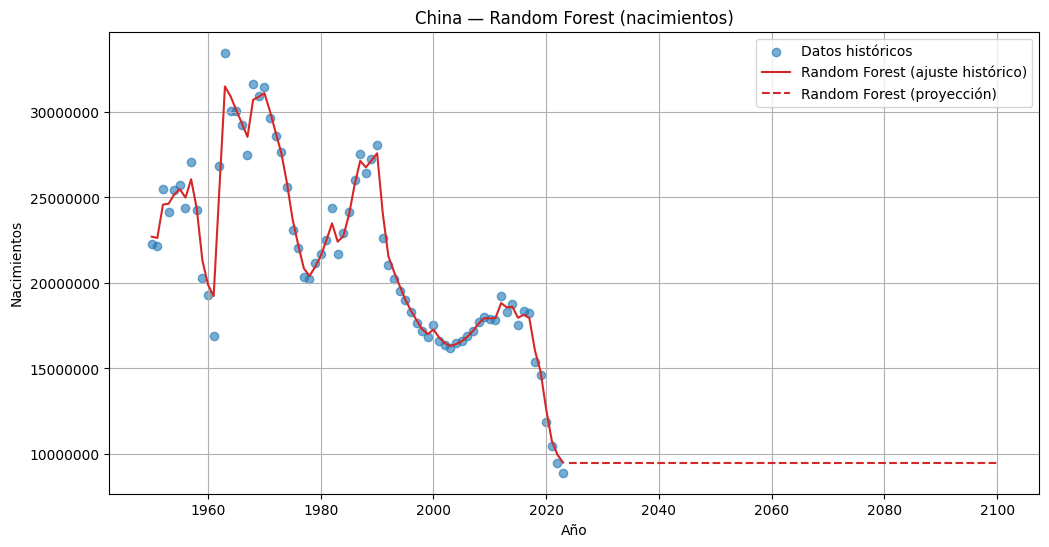

In [21]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_china_historico["Year"],
    df_china_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_china_historico["Year"],
    predicciones_rf_china,
    color="tab:red",
    label="Random Forest (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_china_futuras,
    color="tab:red",
    linestyle="--",
    label="Random Forest (proyección)"
)

plt.title("China — Random Forest (nacimientos)")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## 7. Comparación de los tres modelos (China)

Ponemos los tres modelos en una sola gráfica para comparar los valores reales contra
las predicciones de cada uno.

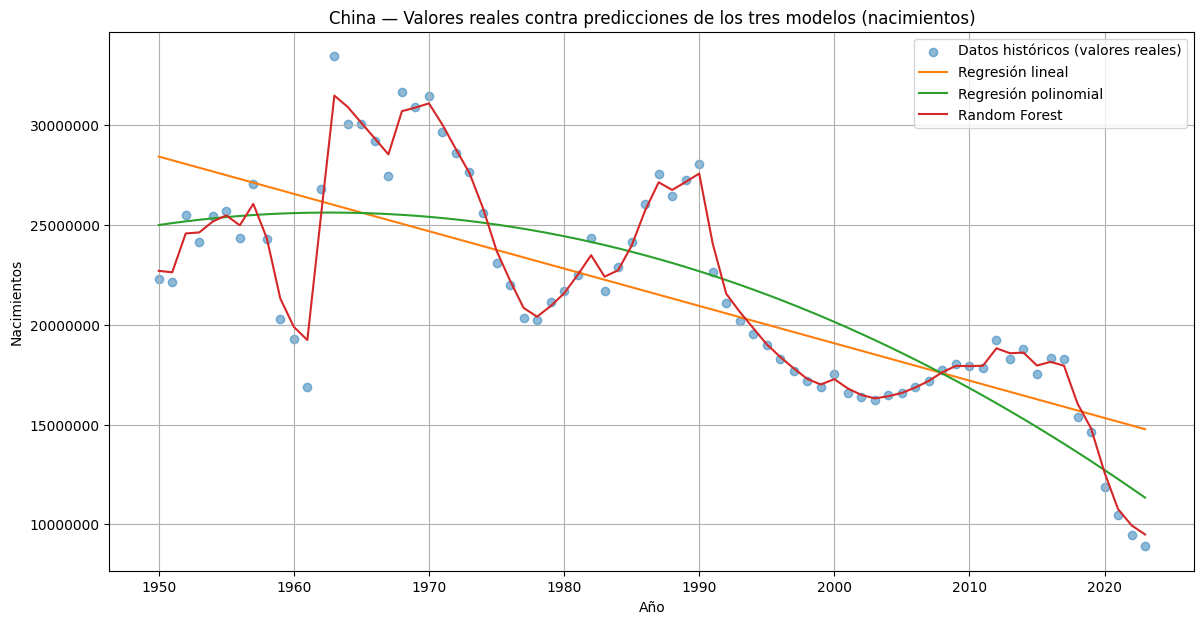

In [22]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_china_historico["Year"],
    df_china_historico["births"],
    label="Datos históricos (valores reales)",
    alpha=0.5
)

plt.plot(
    df_china_historico["Year"],
    predicciones_lineal_china,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    df_china_historico["Year"],
    predicciones_polinomiales_china,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    df_china_historico["Year"],
    predicciones_rf_china,
    color="tab:red",
    label="Random Forest"
)

plt.title("China — Valores reales contra predicciones de los tres modelos (nacimientos)")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

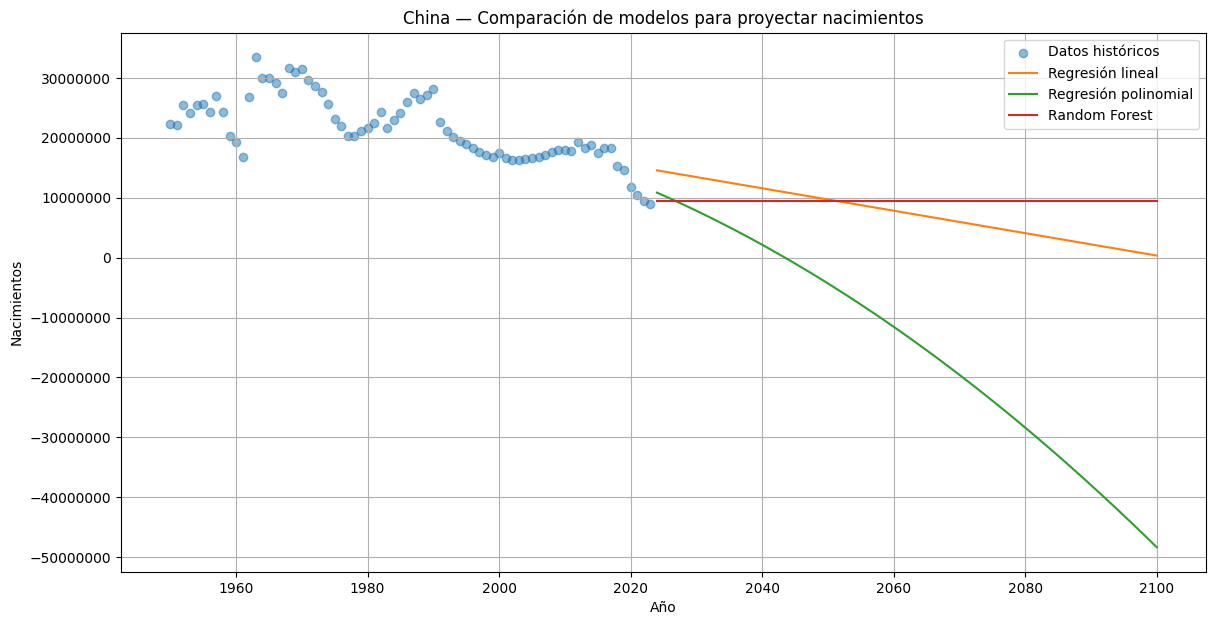

In [23]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_china_historico["Year"],
    df_china_historico["births"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_china_futuras,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_china_futuras,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_china_futuras,
    color="tab:red",
    label="Random Forest"
)

plt.title("China — Comparación de modelos para proyectar nacimientos")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

También comparamos los números, usando la misma función de tabla del notebook original.

In [24]:
anios_tabla = [2030, 2050, 2075, 2100]
indice = anios_futuros.flatten()


def construir_tabla(owid, lineal, polinomial, rf):
    tabla = pd.DataFrame(
        {
            "OWID": owid.set_index("Year").reindex(indice).to_numpy().ravel(),
            "Regresión lineal": lineal,
            "Regresión polinomial": polinomial,
            "Random Forest": rf,
        },
        index=indice
    )
    tabla.index.name = "Año"
    return tabla.loc[anios_tabla]


print("CHINA — NACIMIENTOS")
display(
    construir_tabla(
        df_china_proyectado[["Year", "births"]],
        predicciones_lineal_china_futuras,
        predicciones_polinomiales_china_futuras,
        predicciones_rf_china_futuras
    ).style.format("{:,.0f}")
)

CHINA — NACIMIENTOS


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"8,359,513","13,456,651","7,830,199","9,489,420"
2050,"7,371,348","9,712,484","-4,298,790","9,489,420"
2075,"4,909,046","5,032,277","-23,867,936","9,489,420"
2100,"3,099,844","352,069","-48,334,758","9,489,420"


### Observación (China)

Se repite el mismo comportamiento que vimos en el notebook original con México:
la **regresión lineal** solo puede trazar una recta, la **polinomial** sigue mucho mejor
la curva de los datos históricos pero se dispara al proyectar, y el **Random Forest**
se ajusta casi perfecto al pasado pero se queda plano después de 2023, porque nunca vio
años posteriores.

---

# EJERCICIO 2 — MÉXICO DESDE EL AÑO 2000

En este ejercicio trabajamos solamente con México y, además, únicamente con los
registros **a partir del año 2000**. Se analizan las dos variables: **nacimientos** y
**defunciones**.

## 1. Extracción de los datos de México

In [25]:
pais = "Mexico"

df_mexico = df[df["Entity"] == pais]

print("Rango de años:", df_mexico["Year"].min(), "-", df_mexico["Year"].max())
print("Número de filas:", df_mexico.shape[0])

df_mexico.head()

Rango de años: 1950 - 2100
Número de filas: 151


,Entity,Code,Year,deaths_estimates,deaths_projected,births_estimates,births_projected,births,deaths
22801,Mexico,MEX,1950,596771.0,NaN,1358501.0,NaN,1358501.0,596771.0
22802,Mexico,MEX,1951,588791.0,NaN,1392106.0,NaN,1392106.0,588791.0
22803,Mexico,MEX,1952,582415.0,NaN,1423352.0,NaN,1423352.0,582415.0
22804,Mexico,MEX,1953,565876.0,NaN,1454762.0,NaN,1454762.0,565876.0
22805,Mexico,MEX,1954,552321.0,NaN,1488719.0,NaN,1488719.0,552321.0


## 2. Filtro temporal: desde el año 2000

In [26]:
df_mexico_2000 = df_mexico[
    df_mexico["Year"] >= 2000
]

print("Rango de años:", df_mexico_2000["Year"].min(), "-", df_mexico_2000["Year"].max())
print("Número de filas:", df_mexico_2000.shape[0])

Rango de años: 2000 - 2100
Número de filas: 101


Igual que en el notebook original, separamos los datos históricos (hasta 2023) de las
proyecciones de OWID. Los modelos se entrenan únicamente con los datos históricos, que
en este ejercicio son los del periodo **2000–2023**.

In [27]:
df_mexico_historico = df_mexico_2000[
    df_mexico_2000["Year"] <= 2023
]

df_mexico_proyectado = df_mexico_2000[
    df_mexico_2000["Year"] > 2023
]

print("Histórico  ->", df_mexico_historico.shape, "| años:", df_mexico_historico["Year"].min(), "a", df_mexico_historico["Year"].max())
print("Proyectado ->", df_mexico_proyectado.shape, "| años:", df_mexico_proyectado["Year"].min(), "a", df_mexico_proyectado["Year"].max())

Histórico  -> (24, 9) | años: 2000 a 2023
Proyectado -> (77, 9) | años: 2024 a 2100


## 3. Datos resultantes: nacimientos y defunciones

In [28]:
# Comprobamos que no falten datos
df_mexico_historico[["Year", "births", "deaths"]].isna().sum()

Year      0
births    0
deaths    0
dtype: int64

In [29]:
df_mexico_historico[["Entity", "Year", "births", "deaths"]]

,Entity,Year,births,deaths
22851,Mexico,2000,2385977.0,540567.0
22852,Mexico,2001,2380261.0,543803.0
22853,Mexico,2002,2374140.0,553391.0
22854,Mexico,2003,2351177.0,563140.0
22855,Mexico,2004,2335226.0,575925.0
22856,Mexico,2005,2318498.0,585859.0
22857,Mexico,2006,2303997.0,597892.0
22858,Mexico,2007,2296268.0,611318.0
22859,Mexico,2008,2297950.0,627177.0
22860,Mexico,2009,2303532.0,642292.0


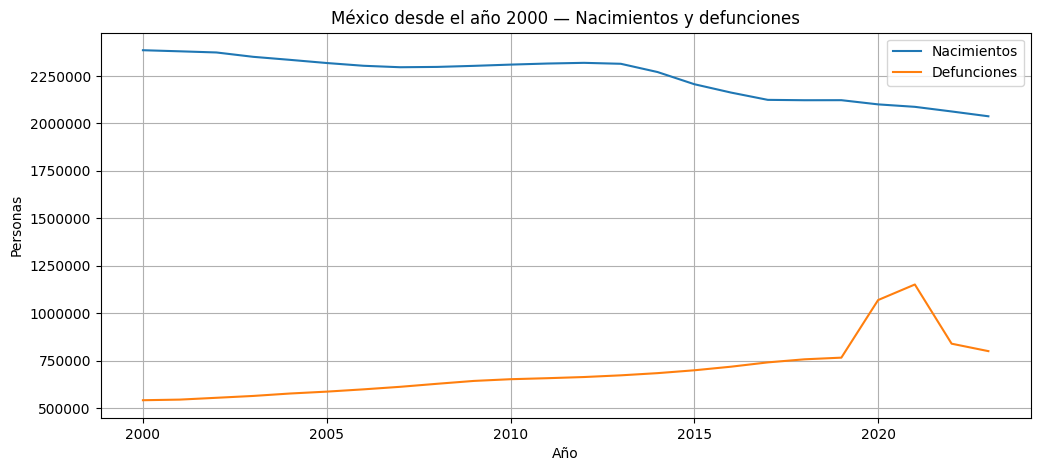

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_mexico_historico["Year"],
    df_mexico_historico["births"],
    label="Nacimientos"
)

plt.plot(
    df_mexico_historico["Year"],
    df_mexico_historico["deaths"],
    label="Defunciones"
)

plt.title("México desde el año 2000 — Nacimientos y defunciones")
plt.xlabel("Año")
plt.ylabel("Personas")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

## 4. Preparación de las variables

La variable predictora **X** vuelve a ser el año. Las variables objetivo son los
nacimientos y las defunciones.

In [31]:
X_mexico = df_mexico_historico[["Year"]]

y_mexico_nacimientos = df_mexico_historico["births"]
y_mexico_defunciones = df_mexico_historico["deaths"]

print("X_mexico.shape:", X_mexico.shape)
print("y_mexico_nacimientos.shape:", y_mexico_nacimientos.shape)
print("y_mexico_defunciones.shape:", y_mexico_defunciones.shape)

X_mexico.shape: (24, 1)
y_mexico_nacimientos.shape: (24,)
y_mexico_defunciones.shape: (24,)


In [32]:
# Variables polinomiales de grado 2 para este subconjunto
poly_mexico = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_mexico_poly = poly_mexico.fit_transform(X_mexico)

anios_futuros_poly_mexico = poly_mexico.transform(
    X_futuro
)

X_mexico_poly[:5]

array([[2.000000e+03, 4.000000e+06],
       [2.001000e+03, 4.004001e+06],
       [2.002000e+03, 4.008004e+06],
       [2.003000e+03, 4.012009e+06],
       [2.004000e+03, 4.016016e+06]])

---

## 5. NACIMIENTOS de México (desde 2000)

### 5.1 Regresión lineal — Nacimientos

In [33]:
modelo_lineal_mx_nac = LinearRegression()

modelo_lineal_mx_nac.fit(
    X_mexico,
    y_mexico_nacimientos
)

predicciones_lineal_mx_nac = modelo_lineal_mx_nac.predict(X_mexico)

predicciones_lineal_mx_nac_futuras = modelo_lineal_mx_nac.predict(X_futuro)

print("Pendiente (a):", modelo_lineal_mx_nac.coef_[0])
print("Intercepto (b):", modelo_lineal_mx_nac.intercept_)

Pendiente (a): -14819.746956521736
Intercepto (b): 32055962.503043473


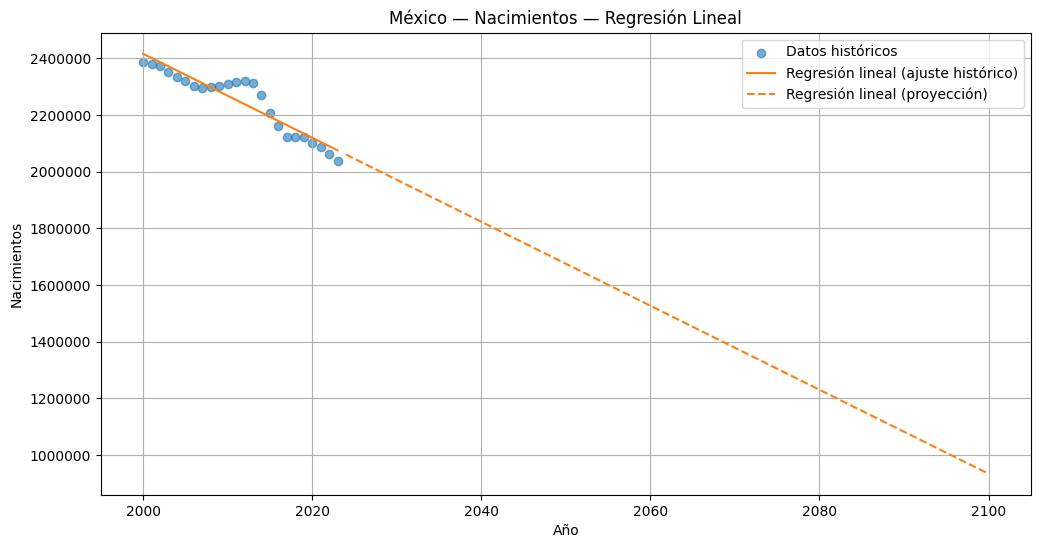

In [34]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_lineal_mx_nac,
    color="tab:orange",
    label="Regresión lineal (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_mx_nac_futuras,
    color="tab:orange",
    linestyle="--",
    label="Regresión lineal (proyección)"
)

plt.title("México — Nacimientos — Regresión Lineal")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 5.2 Regresión polinomial — Nacimientos

In [35]:
modelo_polinomial_mx_nac = LinearRegression()

modelo_polinomial_mx_nac.fit(
    X_mexico_poly,
    y_mexico_nacimientos
)

predicciones_polinomiales_mx_nac = modelo_polinomial_mx_nac.predict(
    X_mexico_poly
)

predicciones_polinomiales_mx_nac_futuras = modelo_polinomial_mx_nac.predict(
    anios_futuros_poly_mexico
)

print(predicciones_polinomiales_mx_nac_futuras[:10])

[1997085.12252998 1966975.08585024 1935688.87303782 1903226.48409271
 1869587.91901541 1834773.17780542 1798782.26046276 1761615.16698742
 1723271.89737892 1683752.4516387 ]


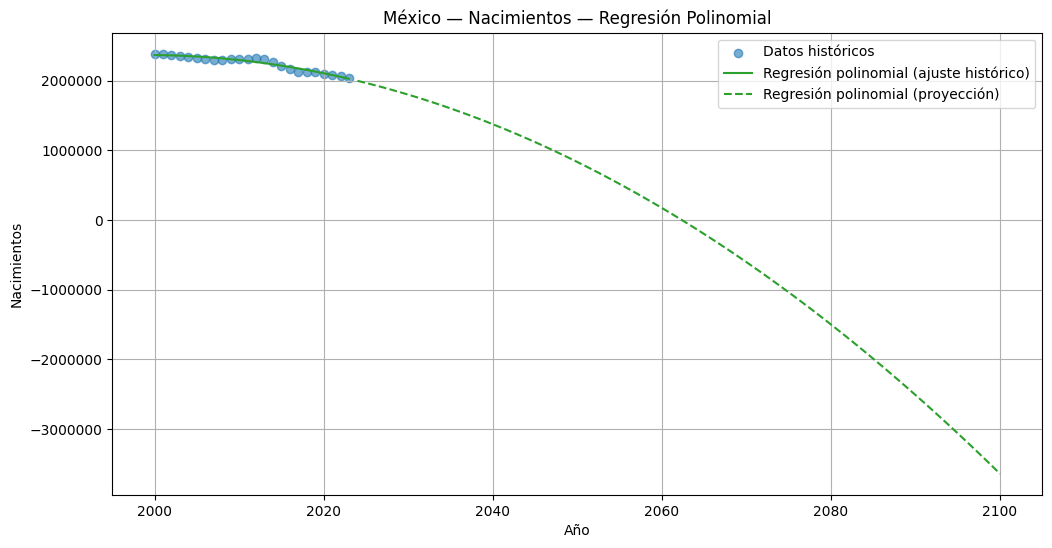

In [36]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_polinomiales_mx_nac,
    color="tab:green",
    label="Regresión polinomial (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_mx_nac_futuras,
    color="tab:green",
    linestyle="--",
    label="Regresión polinomial (proyección)"
)

plt.title("México — Nacimientos — Regresión Polinomial")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 5.3 Random Forest Regressor — Nacimientos

In [37]:
modelo_rf_mx_nac = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_rf_mx_nac.fit(
    X_mexico,
    y_mexico_nacimientos
)

predicciones_rf_mx_nac = modelo_rf_mx_nac.predict(X_mexico)

predicciones_rf_mx_nac_futuras = modelo_rf_mx_nac.predict(X_futuro)

print(predicciones_rf_mx_nac_futuras[:10])

[2051955.27 2051955.27 2051955.27 2051955.27 2051955.27 2051955.27
 2051955.27 2051955.27 2051955.27 2051955.27]


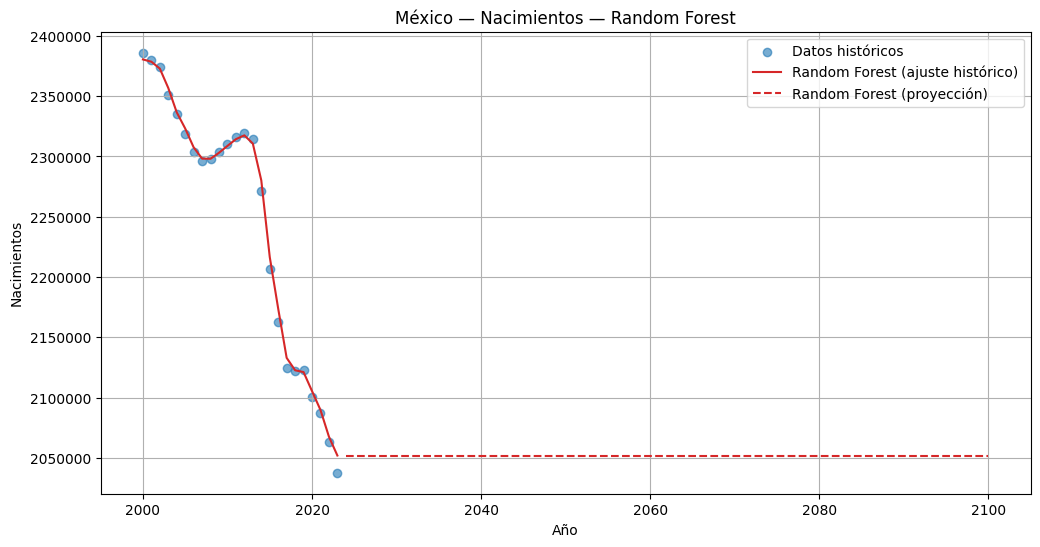

In [38]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["births"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_rf_mx_nac,
    color="tab:red",
    label="Random Forest (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_mx_nac_futuras,
    color="tab:red",
    linestyle="--",
    label="Random Forest (proyección)"
)

plt.title("México — Nacimientos — Random Forest")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

---

## 6. DEFUNCIONES de México (desde 2000)

La variable predictora sigue siendo la misma (`X_mexico`). Lo único que cambia es la
variable objetivo, igual que en el notebook original.

### 6.1 Regresión lineal — Defunciones

In [39]:
modelo_lineal_mx_def = LinearRegression()

modelo_lineal_mx_def.fit(
    X_mexico,
    y_mexico_defunciones
)

predicciones_lineal_mx_def = modelo_lineal_mx_def.predict(X_mexico)

predicciones_lineal_mx_def_futuras = modelo_lineal_mx_def.predict(X_futuro)

print("Pendiente (a):", modelo_lineal_mx_def.coef_[0])
print("Intercepto (b):", modelo_lineal_mx_def.intercept_)

Pendiente (a): 17578.816521739132
Intercepto (b): -34663868.933478266


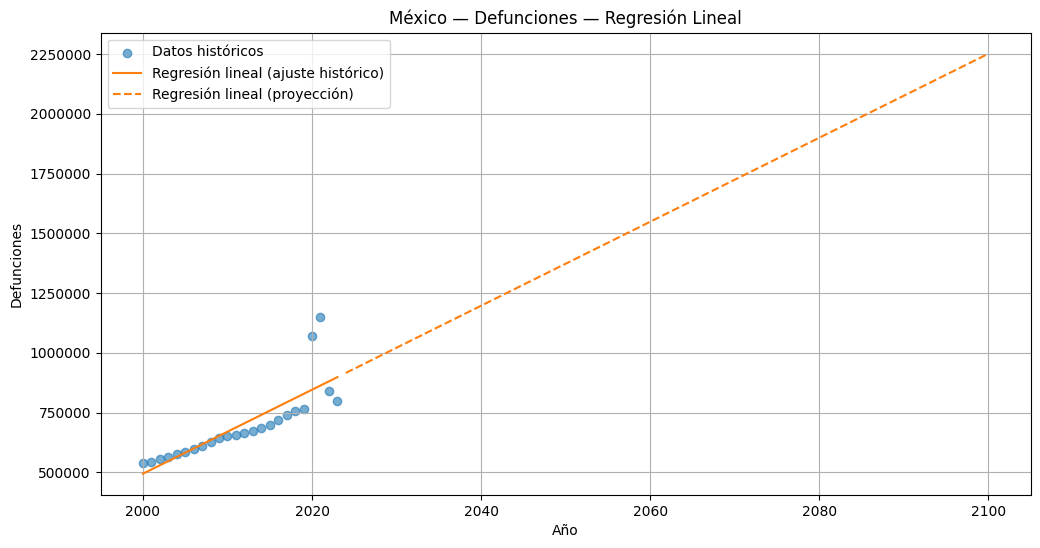

In [40]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["deaths"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_lineal_mx_def,
    color="tab:orange",
    label="Regresión lineal (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_mx_def_futuras,
    color="tab:orange",
    linestyle="--",
    label="Regresión lineal (proyección)"
)

plt.title("México — Defunciones — Regresión Lineal")
plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 6.2 Regresión polinomial — Defunciones

In [41]:
modelo_polinomial_mx_def = LinearRegression()

modelo_polinomial_mx_def.fit(
    X_mexico_poly,
    y_mexico_defunciones
)

predicciones_polinomiales_mx_def = modelo_polinomial_mx_def.predict(
    X_mexico_poly
)

predicciones_polinomiales_mx_def_futuras = modelo_polinomial_mx_def.predict(
    anios_futuros_poly_mexico
)

print(predicciones_polinomiales_mx_def_futuras[:10])

[ 985711.50197697 1020103.70940733 1055789.25460052 1092768.13755608
 1131040.35827351 1170605.91675329 1211464.81299543 1253617.04699993
 1297062.61876631 1341801.52829504]


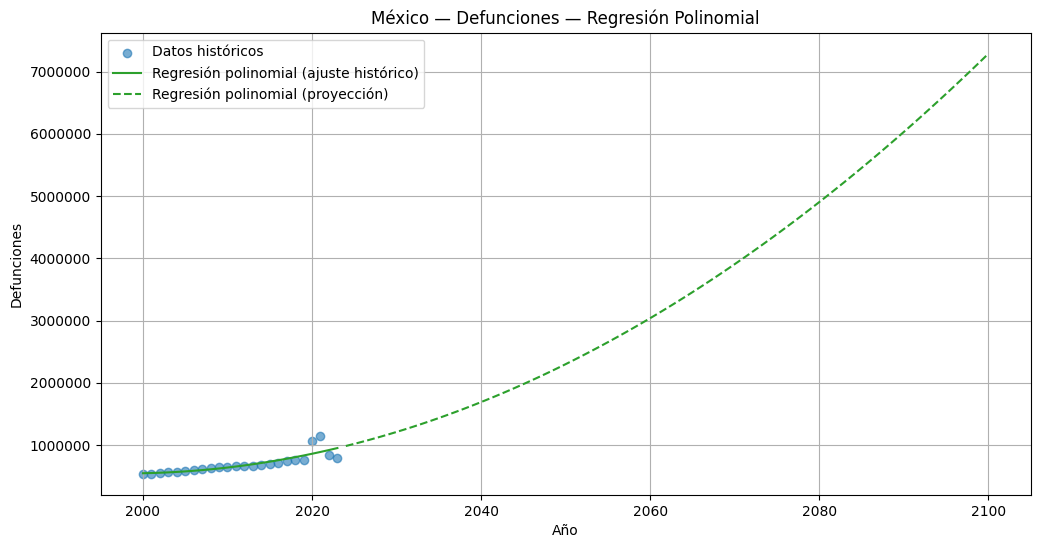

In [42]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["deaths"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_polinomiales_mx_def,
    color="tab:green",
    label="Regresión polinomial (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_mx_def_futuras,
    color="tab:green",
    linestyle="--",
    label="Regresión polinomial (proyección)"
)

plt.title("México — Defunciones — Regresión Polinomial")
plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 6.3 Random Forest Regressor — Defunciones

In [43]:
modelo_rf_mx_def = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

modelo_rf_mx_def.fit(
    X_mexico,
    y_mexico_defunciones
)

predicciones_rf_mx_def = modelo_rf_mx_def.predict(X_mexico)

predicciones_rf_mx_def_futuras = modelo_rf_mx_def.predict(X_futuro)

print(predicciones_rf_mx_def_futuras[:10])

[838792.89 838792.89 838792.89 838792.89 838792.89 838792.89 838792.89
 838792.89 838792.89 838792.89]


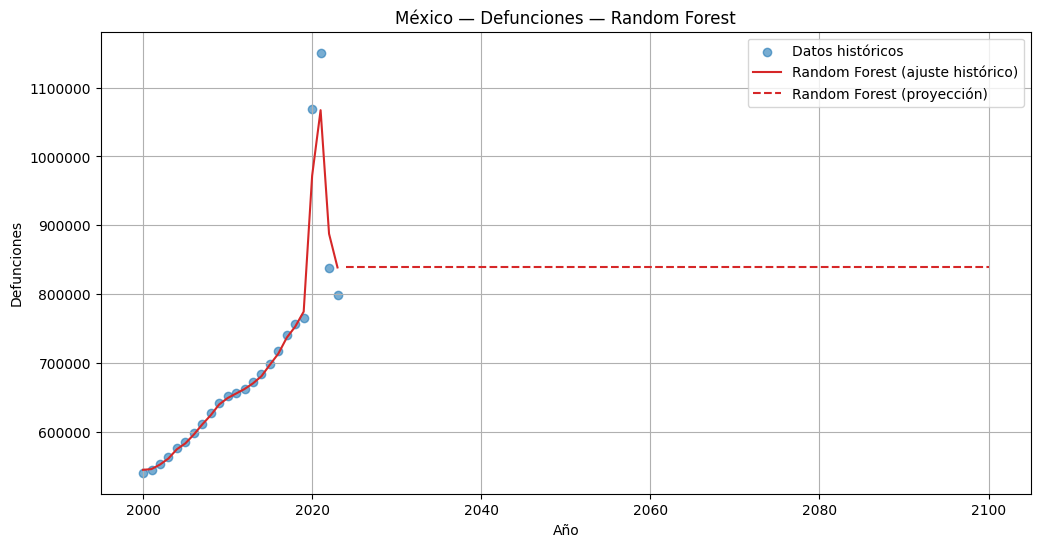

In [44]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["deaths"],
    label="Datos históricos",
    alpha=0.6
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_rf_mx_def,
    color="tab:red",
    label="Random Forest (ajuste histórico)"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_mx_def_futuras,
    color="tab:red",
    linestyle="--",
    label="Random Forest (proyección)"
)

plt.title("México — Defunciones — Random Forest")
plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

---

## 7. Comparación de resultados (México desde 2000)

### 7.1 Nacimientos: valores reales contra predicciones

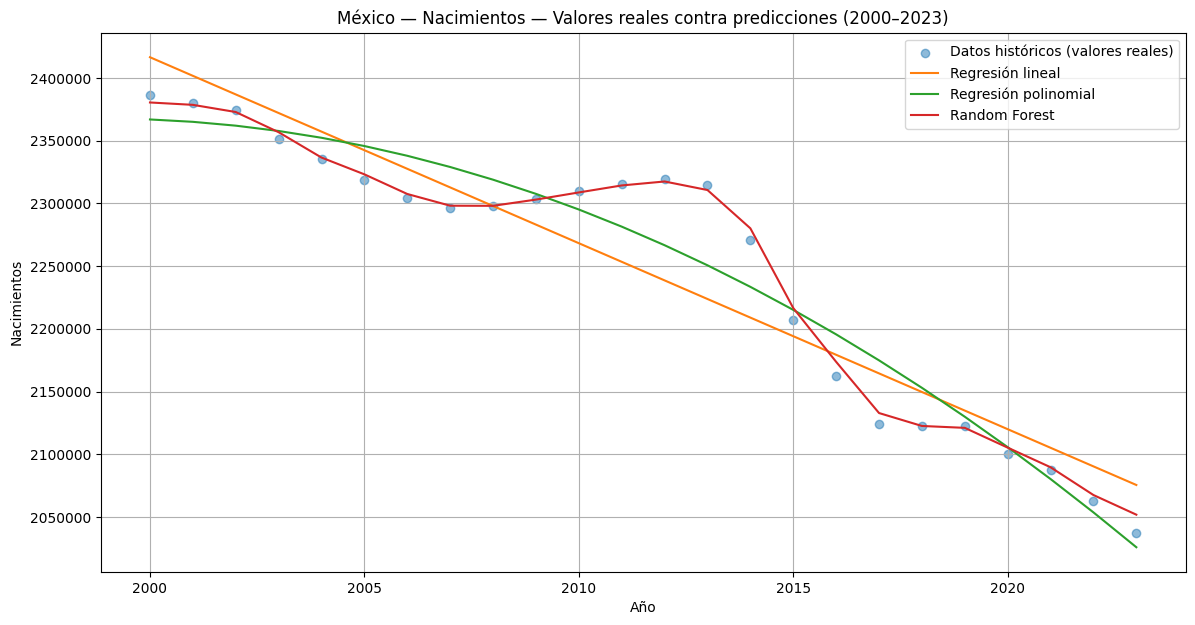

In [45]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["births"],
    label="Datos históricos (valores reales)",
    alpha=0.5
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_lineal_mx_nac,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_polinomiales_mx_nac,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_rf_mx_nac,
    color="tab:red",
    label="Random Forest"
)

plt.title("México — Nacimientos — Valores reales contra predicciones (2000–2023)")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 7.2 Defunciones: valores reales contra predicciones

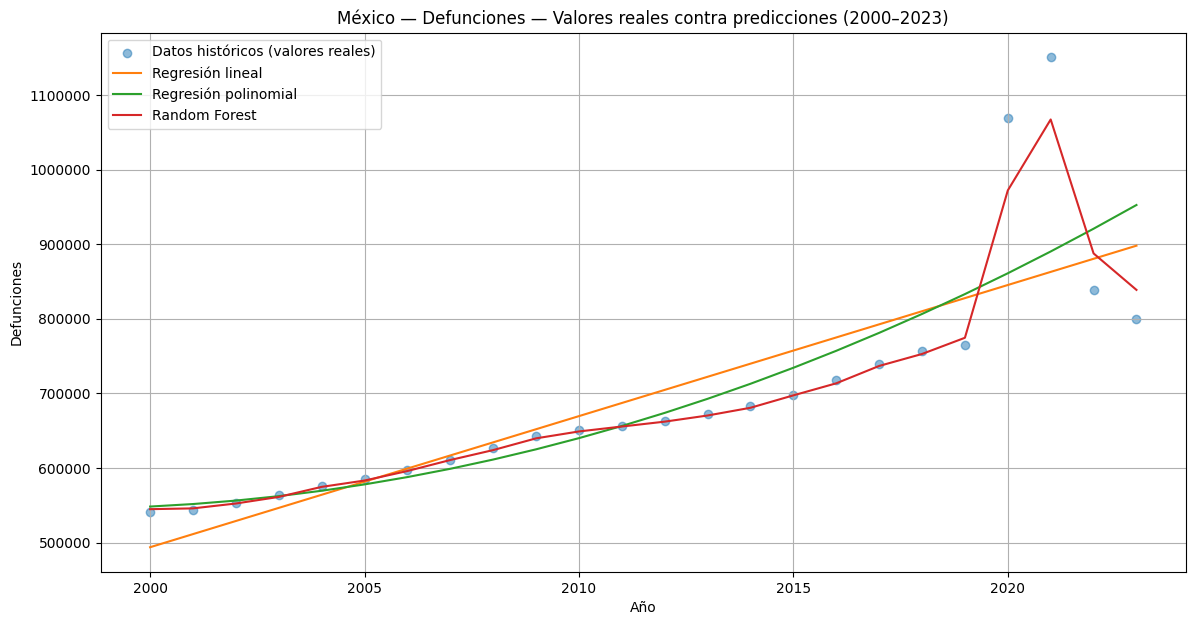

In [46]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["deaths"],
    label="Datos históricos (valores reales)",
    alpha=0.5
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_lineal_mx_def,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_polinomiales_mx_def,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    df_mexico_historico["Year"],
    predicciones_rf_mx_def,
    color="tab:red",
    label="Random Forest"
)

plt.title("México — Defunciones — Valores reales contra predicciones (2000–2023)")
plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 7.3 Proyecciones de los tres modelos

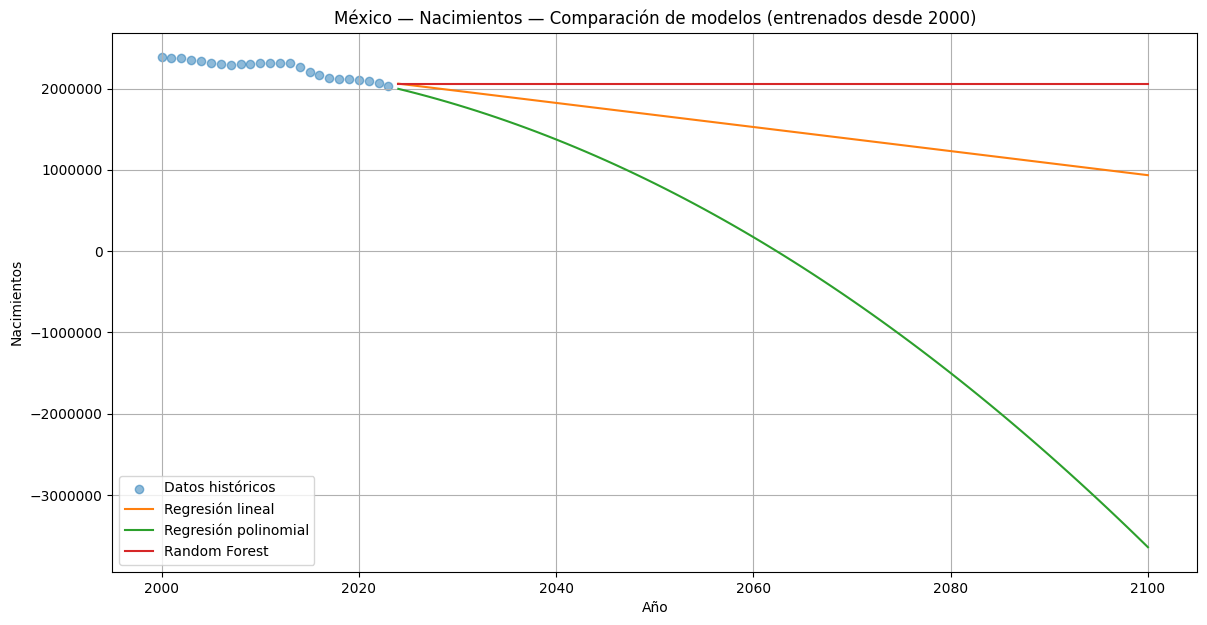

In [47]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["births"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_mx_nac_futuras,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_mx_nac_futuras,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_mx_nac_futuras,
    color="tab:red",
    label="Random Forest"
)

plt.title("México — Nacimientos — Comparación de modelos (entrenados desde 2000)")
plt.xlabel("Año")
plt.ylabel("Nacimientos")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

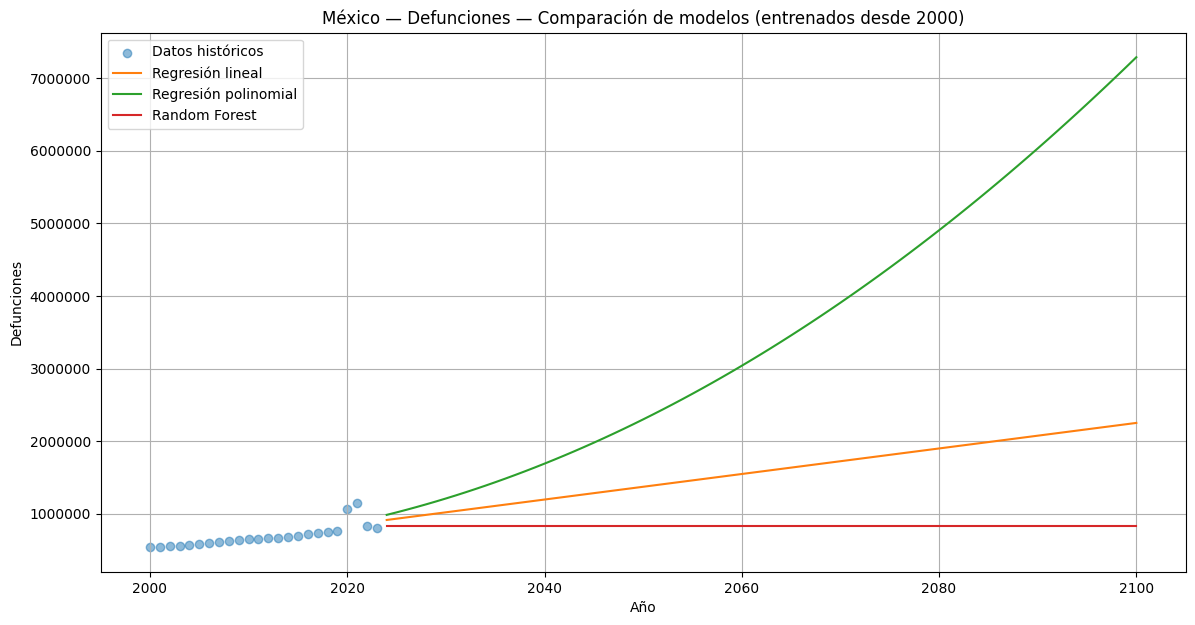

In [48]:
plt.figure(figsize=(14, 7))

plt.scatter(
    df_mexico_historico["Year"],
    df_mexico_historico["deaths"],
    label="Datos históricos",
    alpha=0.5
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_lineal_mx_def_futuras,
    color="tab:orange",
    label="Regresión lineal"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_polinomiales_mx_def_futuras,
    color="tab:green",
    label="Regresión polinomial"
)

plt.plot(
    anios_futuros.flatten(),
    predicciones_rf_mx_def_futuras,
    color="tab:red",
    label="Random Forest"
)

plt.title("México — Defunciones — Comparación de modelos (entrenados desde 2000)")
plt.xlabel("Año")
plt.ylabel("Defunciones")

plt.ticklabel_format(style="plain", axis="y", useOffset=False)
plt.legend()
plt.grid()
plt.show()

### 7.4 Resumen numérico

Usamos la misma función `construir_tabla` del notebook original para ver los números de
nacimientos y de defunciones por separado.

In [49]:
print("MÉXICO (desde 2000) — NACIMIENTOS")
display(
    construir_tabla(
        df_mexico_proyectado[["Year", "births"]],
        predicciones_lineal_mx_nac_futuras,
        predicciones_polinomiales_mx_nac_futuras,
        predicciones_rf_mx_nac_futuras
    ).style.format("{:,.0f}")
)

print("MÉXICO (desde 2000) — DEFUNCIONES")
display(
    construir_tabla(
        df_mexico_proyectado[["Year", "deaths"]],
        predicciones_lineal_mx_def_futuras,
        predicciones_polinomiales_mx_def_futuras,
        predicciones_rf_mx_def_futuras
    ).style.format("{:,.0f}")
)

MÉXICO (desde 2000) — NACIMIENTOS


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"1,934,285","1,971,876","1,798,782","2,051,955"
2050,"1,643,767","1,675,481","831,967","2,051,955"
2075,"1,340,246","1,304,988","-1,038,151","2,051,955"
2100,"1,098,210","934,494","-3,643,380","2,051,955"


MÉXICO (desde 2000) — DEFUNCIONES


,OWID,Regresión lineal,Regresión polinomial,Random Forest
Año,,,,
2030,"907,843","1,021,129","1,211,465","838,793"
2050,"1,291,889","1,372,705","2,300,244","838,793"
2075,"1,685,181","1,812,175","4,388,720","838,793"
2100,"1,793,462","2,251,646","7,285,532","838,793"


---

## 8. Conclusión de los ejercicios

En los dos ejercicios se usó exactamente la misma metodología del notebook original:
el año como variable predictora, los datos históricos hasta 2023 para entrenar y una
proyección de 2024 a 2100 con los tres modelos.

Lo que se observa es lo mismo que en la práctica original, sin importar el país ni el
periodo que se use:

- La **regresión lineal** solo traza una recta, así que no puede seguir los cambios de
  tendencia.
- La **regresión polinomial** se ajusta mucho mejor a los datos históricos porque puede
  hacer una curva, pero al proyectar tan lejos los valores se disparan.
- El **Random Forest** se ajusta casi perfecto al pasado, pero al proyectar se queda
  plano, porque no sabe extrapolar fuera del rango de años con el que se entrenó.

En el ejercicio de México desde el año 2000 se ve además que, al entrenar con menos
años, los modelos cambian bastante respecto al notebook original (que entrenaba desde
1950): con los datos recientes los nacimientos ya solo van a la baja, así que la recta
ahora sí baja en lugar de subir.